In [1]:
import pandas as pd
import glob

# Path to all CSVs (adjust this to your Kaggle download folder)
path = "./CICIDS2017/"  

# Load all CSV files into a list
all_files = glob.glob(path + "*.csv")

# Combine into one DataFrame
df_list = [pd.read_csv(file) for file in all_files]
df = pd.concat(df_list, ignore_index=True)
df = df.sample(n=20000, random_state=42)

print("Combined shape:", df.shape)
print("Columns:", df.columns[:10], "...")
print("Unique labels:", df[' Label'].unique())


Combined shape: (20000, 79)
Columns: Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std'],
      dtype='object') ...
Unique labels: ['BENIGN' 'DoS Hulk' 'PortScan' 'DDoS' 'DoS slowloris' 'DoS GoldenEye'
 'FTP-Patator' 'DoS Slowhttptest' 'Bot' 'SSH-Patator' 'Web Attack � XSS'
 'Web Attack � Brute Force' 'Infiltration']


In [2]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim
    

In [3]:
SEED = 42
NUM_FEATURES = 10

In [4]:
# df.dtypes

In [5]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

# Strip spaces from column names
df.columns = df.columns.str.strip()

In [6]:
categorical_cols = df.select_dtypes(include='object').columns
label_encoders = {}

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f"\nColumn: {col}")
    print(dict(zip(le.classes_, le.transform(le.classes_))))


Column: Label
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP-Patator': 7, 'Infiltration': 8, 'PortScan': 9, 'SSH-Patator': 10, 'Web Attack � Brute Force': 11, 'Web Attack � XSS': 12}


In [7]:
feature_names = df.columns
X = df.drop('Label', axis=1)   # note: 'Label' (no space after cleaning)
y = df['Label']

# Train/test split
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution (train): {np.bincount(y_train)}")

Original class distribution (train): [12867    15   676    57  1272    33    34    51     1   940    28     2
     6]


In [8]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [9]:
pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")

Features Selected: 
Principal Component 1: most important feature is 'Flow IAT Max'
Principal Component 2: most important feature is 'Total Backward Packets'
Principal Component 3: most important feature is 'Fwd IAT Min'
Principal Component 4: most important feature is 'Avg Fwd Segment Size'
Principal Component 5: most important feature is 'min_seg_size_forward'
Principal Component 6: most important feature is 'ACK Flag Count'
Principal Component 7: most important feature is 'Active Max'
Principal Component 8: most important feature is 'Fwd IAT Min'
Principal Component 9: most important feature is 'Active Mean'
Principal Component 10: most important feature is 'URG Flag Count'


In [10]:
X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape, X_test.shape)

(15982, 10) (3996, 10)


In [11]:
# from qiskit_ibm_runtime import QiskitRuntimeService
# QiskitRuntimeService.save_account(
#     channel="ibm_quantum",  
#     token="v-uYI15U6wsQ0TyrumMduQcg6Jm99UMi09CSA05q9AFk",
#     overwrite=True
# )

# service = QiskitRuntimeService(channel="ibm_quantum")


# # v-uYI15U6wsQ0TyrumMduQcg6Jm99UMi09CSA05q9AFk

In [12]:
def create_sequential_batches(X_train, y_train, X_test, y_test, train_batch_size=300, test_batch_size=100):
    train_batches = []
    test_batches = []
    num_batches = min(len(X_train) // train_batch_size, len(X_test) // test_batch_size)
    for i in range(num_batches):
        train_start = i * train_batch_size
        train_end = train_start + train_batch_size
        test_start = i * test_batch_size
        test_end = test_start + test_batch_size
        train_batches.append((X_train[train_start:train_end], y_train[train_start:train_end]))
        test_batches.append((X_test[test_start:test_end], y_test[test_start:test_end]))
    return train_batches, test_batches

# Usage:
train_batches, test_batches = create_sequential_batches(X_train, y_train, X_test, y_test)

In [13]:
SEED = 42
# NUM_FEATURES = 4
TRAIN_BATCH_SIZE = 300
TEST_BATCH_SIZE = 100
NUM_BATCHES = 10

from joblib import Parallel, delayed


dev = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

def kernel(x1, x2):
    return kernel_circuit(x1, x2)

def compute_kernel_matrix(X1, X2):
    n_samples_1, n_samples_2 = len(X1), len(X2)
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))
    for i in range(n_samples_1):
        for j in range(n_samples_2):
            probs = kernel_circuit(X1[i], X2[j])
            kernel_matrix[i, j] = probs[0]  # this represents the inner product now
    return kernel_matrix

In [18]:
from sklearn.model_selection import GridSearchCV

# Store metrics
all_test_preds = []
all_test_labels = []
train_accuracies = []
test_accuracies = []


for batch_idx in range(10):
    print(f"\nBatch {batch_idx + 1}/10")

    # Get batch data
    X_batch_train, y_batch_train = train_batches[batch_idx]
    X_batch_test, y_batch_test = test_batches[batch_idx]

    print("- Computing training kernel...")
    K_train = compute_kernel_matrix(X_batch_train, X_batch_train)

    print("- Computing testing kernel...")
    K_test = compute_kernel_matrix(X_batch_test, X_batch_train)

    if batch_idx == 4:
        K_train_4 = K_train
        K_test_4 = K_test

    # Hyperparameter tuning for C
    print("- Tuning C value...")
    param_grid = {"C": [0.1, 1, 10, 20, 30, 40, 50, 60]}
    grid = GridSearchCV(SVC(kernel='precomputed', class_weight='balanced'), param_grid, cv=2)
    grid.fit(K_train, y_batch_train)
    best_model = grid.best_estimator_
    print(f"- Best C: {grid.best_params_['C']}")


    # Predictions
    y_pred = best_model.predict(K_test)
    all_test_preds.append(y_pred)
    all_test_labels.append(y_batch_test)

    # Overfitting check
    train_preds = best_model.predict(K_train)
    train_acc = accuracy_score(y_batch_train, train_preds)
    test_acc = accuracy_score(y_batch_test, y_pred)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"- Train Accuracy: {train_acc:.4f}")
    print(f"- Test Accuracy: {test_acc:.4f}")
    if train_acc - test_acc > 0.10:
        print("- Possible overfitting detected (Train >> Test)")



Batch 1/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 50
- Train Accuracy: 0.9367
- Test Accuracy: 0.9000

Batch 2/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 60
- Train Accuracy: 0.9633
- Test Accuracy: 0.8800

Batch 3/10
- Computing training kernel...


/home/ritvik/Code/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(


- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 0.9533
- Test Accuracy: 0.9100

Batch 4/10
- Computing training kernel...


/home/ritvik/Code/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(


- Computing testing kernel...
- Tuning C value...
- Best C: 50
- Train Accuracy: 0.9467
- Test Accuracy: 0.9400

Batch 5/10
- Computing training kernel...


...

- Computing testing kernel...
- Tuning C value...
- Best C: 60
- Train Accuracy: 0.9800
- Test Accuracy: 0.8800

Batch 9/10
- Computing training kernel...


/home/ritvik/Code/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(


- Computing testing kernel...
- Tuning C value...
- Best C: 40
- Train Accuracy: 0.9267
- Test Accuracy: 0.8400

Batch 10/10
- Computing training kernel...


/home/ritvik/Code/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(


- Computing testing kernel...
- Tuning C value...
- Best C: 60
- Train Accuracy: 0.9500
- Test Accuracy: 0.8900



Final Batched QSVM Accuracy: 0.9000
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.92      0.94       805
           1       0.00      0.00      0.00         0
           2       0.74      0.79      0.76        43
           3       0.00      0.00      0.00         3
           4       0.83      0.80      0.82        87
           5       0.00      0.00      0.00         2
           6       1.00      0.33      0.50         3
           7       0.00      0.00      0.00         1
           9       0.63      0.98      0.77        55
          10       0.00      0.00      0.00         1
          12       0.00      0.00      0.00         0

    accuracy                           0.90      1000
   macro avg       0.38      0.35      0.34      1000
weighted avg       0.91      0.90      0.90      1000



/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/sit

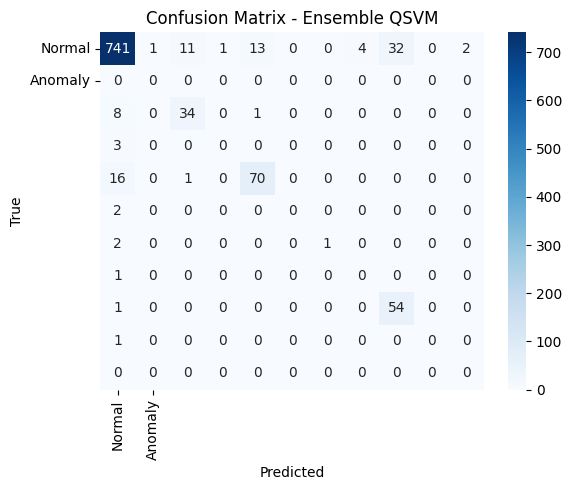

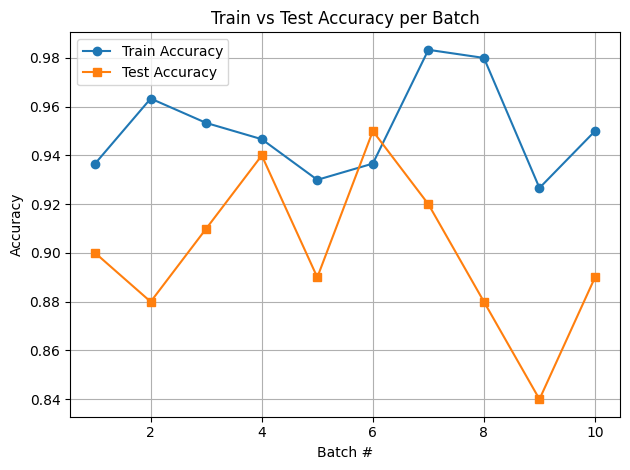

In [19]:
# Final evaluation
all_test_preds = np.concatenate(all_test_preds)
all_test_labels = np.concatenate(all_test_labels)

final_acc = accuracy_score(all_test_labels, all_test_preds)
print(f"\nFinal Batched QSVM Accuracy: {final_acc:.4f}")
print("Classification Report:\n", classification_report(all_test_labels, all_test_preds))

# Confusion matrix
cm = confusion_matrix(all_test_labels, all_test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix - Ensemble QSVM")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# Plot train vs test accuracy
plt.plot(range(1, 11), train_accuracies, label="Train Accuracy", marker='o')
plt.plot(range(1, 11), test_accuracies, label="Test Accuracy", marker='s')
plt.title("Train vs Test Accuracy per Batch")
plt.xlabel("Batch #")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [35]:
from sklearn.metrics import f1_score

f1 = f1_score(all_test_labels, all_test_preds, average='macro')

print(f"F1 Score QSVM: {f1:.4f}")

from sklearn.metrics import average_precision_score, precision_recall_curve, auc

auprc_qsvm = average_precision_score(all_test_labels, all_test_preds, average="macro")

print(f"AUPRC QSVM: {auprc_qsvm:.4f}")

F1 Score QSVM: 0.3442


ValueError: Expected 2D array, got 1D array instead:
array=[ 0  9  0  0  9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  9  0
  9  4  4  0  0  0  0  0  0  4  0  0  4  0  0  0  0  0  0  0  0  0  0  0
  9  0  0  0  0  0  0  0  4  0  0  0  0  0  9  2  0  0  4  0  0  0  0  0
  0  0  0  0  0  0  0  0  4  0  4  0  4  0  0  0  0  2  0  0  2  4  0  0
  0  0  0  4  0  0  2  0  0  0  0  4  0  0  0  0  0  9  0  9  0  0  0  0
  0  0  0  4  2  0  0  0  0  2  9  0  0  9  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  9  0  0  0  4  0  0  0  2  0  4  0  4  0  9  9  0  9  0  0
  0  0  0  0  0  0  9  9  0  0  4  0  0  9  0  0  2  0  4  0  4  0  0  4
  0  0  0  0  0  0  0  0  0  0  0  4  0  0  9  0  0  4  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  9  0  0  0  0  0  0  0
  0  0  9  0  0  0  4  0  0  4  0  4  0  0  0  4  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  2  0  0  0  0  0  4  0  0  0  9  0  0  0  0  0
  0  4  0  0  0  0  0  0  2  0  0  0  0  0  0  4  0  0  3  0  0  

In [21]:
from sklearn.metrics import roc_curve
def compute_tpr_at_fpr(y_true, y_score, fpr_targets=[0.001, 0.01]):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    print("Min FPR:", fpr.min())
    print("Max FPR:", fpr.max())

    results = {}
    for target in fpr_targets:
        # Always interpolate for robustness
        results[f"TPR@{target*100:.1f}%FPR"] = float(np.interp(target, fpr, tpr))

    # Plot zoomed-in ROC curve
    import matplotlib.pyplot as plt
    plt.plot(fpr, tpr, label="ROC")
    plt.xlim(0, 0.02)   # zoom in to 0–2% FPR
    plt.ylim(0, 1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

    return results


# Example
metrics = compute_tpr_at_fpr(all_test_labels, all_test_preds)
print(metrics)

ValueError: multiclass format is not supported

In [22]:
n_layers = 5
n_classes = len(y.unique())

dev = qml.device("default.qubit", wires=NUM_FEATURES)
# dev = qml.device("qiskit.ibmq", wires=NUM_FEATURES, backend="ibmq_qasm_simulator")

@qml.qnode(dev)
def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifierMulti(nn.Module):
    def __init__(self, n_layers, n_qubits, n_classes):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, n_classes)  # output = n_classes
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # logits for each class

# class QNNClassifier(nn.Module):
#     def __init__(self, n_layers, n_qubits):
#         super().__init__()
#         weight_shapes = {"weights": (n_layers, n_qubits, 3)}
#         self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
#         self.fc = nn.Linear(n_qubits, 1)
    
#     def forward(self, x):
#         x = self.qlayer(x)
#         x = self.fc(x)
#         return x  # No sigmoid here




In [23]:
# Prepare data (example subset)
X_train_tensor = torch.tensor(X_train[:3000], dtype=torch.float32)
y_train_tensor = torch.tensor(y_train[:3000].values, dtype=torch.long)  # long for CE loss
X_test_tensor = torch.tensor(X_test[:1000], dtype=torch.float32)
y_test_tensor = torch.tensor(y_test[:1000].values, dtype=torch.long)

# Dataloader
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Model, loss, optimizer
model_multi = QNNClassifierMulti(n_layers=n_layers, n_qubits=NUM_FEATURES, n_classes=n_classes)
criterion = nn.CrossEntropyLoss() # removed BCEWithLogitsLoss because it is used for binary calssification
optimizer = optim.Adam(model_multi.parameters(), lr=0.01)

# Training loop
epochs = 100
for epoch in range(epochs):
    model_multi.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model_multi(X_batch)              # shape: (batch, n_classes)
        loss = criterion(outputs, y_batch)          # CE loss expects logits + class indices
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    # if (epoch+1) % 10 == 0:
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")


model_multi.eval()
with torch.no_grad():
    logits = model_multi(X_test_tensor)       # (N, n_classes)
    probs = torch.softmax(logits, dim=1)      # class probabilities
    preds = torch.argmax(probs, dim=1).numpy()

acc = accuracy_score(y_test_tensor, preds)
print(f"Multiclass QNN Accuracy: {acc:.4f}")


Epoch 1/100, Loss: 1.5926
Epoch 2/100, Loss: 0.6756
Epoch 3/100, Loss: 0.5178
Epoch 4/100, Loss: 0.4407
Epoch 5/100, Loss: 0.3969
Epoch 6/100, Loss: 0.3651
Epoch 7/100, Loss: 0.3392
Epoch 8/100, Loss: 0.3235
Epoch 9/100, Loss: 0.3074
Epoch 10/100, Loss: 0.2967
Epoch 11/100, Loss: 0.2868
Epoch 12/100, Loss: 0.2802
Epoch 13/100, Loss: 0.2784
Epoch 14/100, Loss: 0.2675
Epoch 15/100, Loss: 0.2604
Epoch 16/100, Loss: 0.2589
Epoch 17/100, Loss: 0.2535
Epoch 18/100, Loss: 0.2528
Epoch 19/100, Loss: 0.2473
Epoch 20/100, Loss: 0.2454
Epoch 21/100, Loss: 0.2418
Epoch 22/100, Loss: 0.2378
Epoch 23/100, Loss: 0.2417
Epoch 24/100, Loss: 0.2357
Epoch 25/100, Loss: 0.2274
Epoch 26/100, Loss: 0.2322
Epoch 27/100, Loss: 0.2238
Epoch 28/100, Loss: 0.2220
Epoch 29/100, Loss: 0.2208
Epoch 30/100, Loss: 0.2209
Epoch 31/100, Loss: 0.2242
Epoch 32/100, Loss: 0.2148
Epoch 33/100, Loss: 0.2144
Epoch 34/100, Loss: 0.2147
Epoch 35/100, Loss: 0.2085
Epoch 36/100, Loss: 0.2106
Epoch 37/100, Loss: 0.2099
Epoch 38/1

In [24]:
print("Classification Report:\n", 
      classification_report(
          y_test_tensor, 
          preds, 
          target_names=[str(c) for c in np.unique(y_test_tensor)]
      ))

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.96      0.96       805
           2       0.86      0.86      0.86        43
           3       0.00      0.00      0.00         3
           4       0.91      0.83      0.87        87
           5       0.00      0.00      0.00         2
           6       0.00      0.00      0.00         3
           7       0.00      0.00      0.00         1
           9       0.75      0.96      0.84        55
          10       0.00      0.00      0.00         1

    accuracy                           0.94      1000
   macro avg       0.39      0.40      0.39      1000
weighted avg       0.93      0.94      0.93      1000



/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


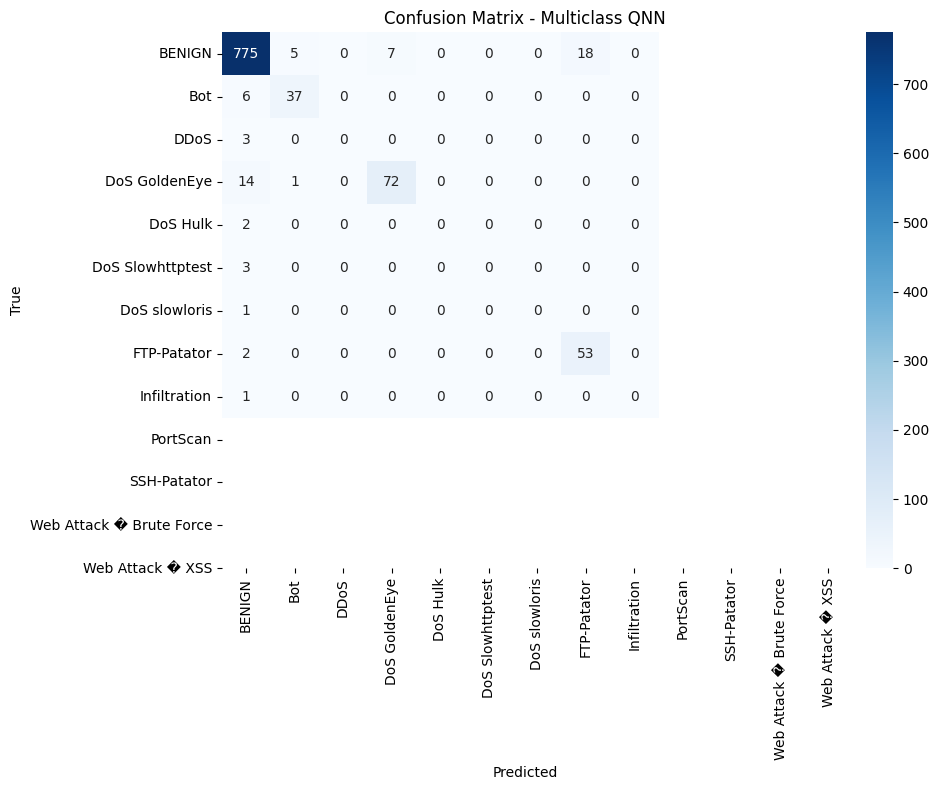

In [25]:
cm = confusion_matrix(y_test_tensor, preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - Multiclass QNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [ ]:
with torch.no_grad():
    y_pred_logits = model_multi(X_test_tensor)  # shape: (N, 1)
    qnn_sigmoid = torch.sigmoid(y_pred_logits).squeeze()  # shape: (N,)
    
    qnn_preds = (qnn_sigmoid > 0.5).int().numpy()

    # Convert to probability distribution over 2 classes: [P(class 0), P(class 1)]
    qnn_probs = torch.stack([1 - qnn_sigmoid, qnn_sigmoid], dim=1).cpu().numpy()  # shape: (N, 2)

In [26]:
qnn_model = model_multi

In [34]:
qsvm_preds = all_test_preds

qsvm_preds = np.concatenate([np.ravel(batch) for batch in all_test_preds])
qnn_preds  = np.concatenate([np.ravel(batch) for batch in qnn_preds])
y_meta     = np.concatenate([np.ravel(batch) for batch in all_test_labels])

qsvm_preds = qsvm_preds.reshape(-1, 1)
qnn_preds  = qnn_preds.reshape(-1, 1)

# y_meta     = np.concatenate(all_test_labels)
qnn_preds = qnn_preds[:len(qsvm_preds)]
X_meta = np.hstack([qsvm_preds, qnn_preds])

# X_meta = np.vstack([qsvm_preds, qnn_preds]).T  # shape: (n_samples, 2)
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the meta-model
meta_model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
meta_model_rf.fit(X_meta, y_meta)  # match y_test slicing
ensemble_rf_preds = meta_model_rf.predict(X_meta)

print("Random Forest Meta-Model Accuracy:", accuracy_score(y_meta, ensemble_rf_preds))
print("\nClassification Report (Random Forest Meta-Model):")
print(classification_report(y_meta, ensemble_rf_preds))

Random Forest Meta-Model Accuracy: 0.908

Classification Report (Random Forest Meta-Model):
              precision    recall  f1-score   support

           0       0.96      0.93      0.94       805
           2       0.74      0.79      0.76        43
           3       0.00      0.00      0.00         3
           4       0.83      0.80      0.82        87
           5       0.00      0.00      0.00         2
           6       1.00      0.33      0.50         3
           7       0.00      0.00      0.00         1
           9       0.63      0.98      0.77        55
          10       0.00      0.00      0.00         1

    accuracy                           0.91      1000
   macro avg       0.46      0.43      0.42      1000
weighted avg       0.91      0.91      0.91      1000



/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [33]:
print("QSVM preds shape:", qsvm_preds.shape)
print("QNN preds shape:", qnn_preds.shape)
print("Labels shape:", y_meta.shape)


QSVM preds shape: (1000, 1)
QNN preds shape: (13000, 1)
Labels shape: (1000,)
